# 04b — Stock-specific linear models

This model-building counterpart to notebook 04 uses the per-stock factor orders and training-fitted orthogonalization saved by notebook 03b. Each stock gets its own OLS model. Coefficients are fitted on the 2017-01-03–2023-12-29 estimation window, then held fixed for the 2024-01-02–2026-10-01 holdout.

Unlike notebook 04, this version does not compare the predefined M0–M3 basket models or produce rolling basket attribution. It evaluates the selected stock-specific models against a market-only benchmark. The holdout is reserved for evaluation, not factor selection, transformation fitting, or regression fitting. Cumulative predicted returns are illustrative, not a trading backtest.

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd().resolve()
while project_root != project_root.parent and not (project_root / "src" / "factor_lens").exists():
    project_root = project_root.parent
if not (project_root / "src" / "factor_lens").exists():
    raise RuntimeError("Open this notebook from the repository root or a subfolder.")
sys.path.insert(0, str(project_root / "src"))

In [2]:
from factor_lens import factor_correlation, factor_selection, stock_specific_model

correlation_results = factor_correlation.get_results()
selection_dir = correlation_results["_out_root"] / "stock_specific_selection_v1"
selection_results = factor_selection.load_results(selection_dir)

res = stock_specific_model.run_models(selection_results)
output_dir = stock_specific_model.save_results(res, selection_results)
print(f"Saved stock-specific model results to: {output_dir}")
print(f"Models fitted: {len(res['summary'])} | models skipped: {len(res['skipped'])}")

Cache hit: factor results already on Drive for this clean data and config -> loading.
Saved stock-specific model results to: factor_lens_local\factors\factors_v1__clean_v1__yahoo_2016-01-01_2026-10-01_v1\stock_specific_selection_v1\regression
Models fitted: 42 | models skipped: 0


## Selected factors and holdout performance

Out-of-sample R-squared is measured relative to the stock's training-period mean. Negative values mean the model's squared errors exceeded that simple baseline. The market-only comparison is fitted using the same training dates and evaluated on the same holdout rows. The factor and model-size charts summarize the stock-specific selections. The AI-close/control comparison is descriptive, not a causal or bootstrap test.

,target,n_factors,factor_order,training_observations,training_r2,holdout_observations,holdout_r2_selected,holdout_r2_market_only,holdout_r2_increment,holdout_correlation
21,KO,4,"[""MKT"", ""LOWVOL"", ""SOFT"", ""SIZE""]",1760,0.612201,690,0.330775,-0.356855,0.687630,0.578947
19,JNJ,5,"[""MKT"", ""LOWVOL"", ""SIZE"", ""SOFT"", ""GRID""]",1760,0.477123,690,0.245638,-0.240613,0.486251,0.496140
32,PG,4,"[""MKT"", ""LOWVOL"", ""SIZE"", ""SOFT""]",1760,0.530582,690,0.311841,-0.166637,0.478478,0.558321
23,MCD,3,"[""MKT"", ""LOWVOL"", ""SOFT""]",1760,0.477559,690,0.251768,-0.172749,0.424517,0.503217
27,MU,5,"[""MKT"", ""SEMI"", ""SIZE"", ""SOFT"", ""GRID""]",1760,0.640148,690,0.602359,0.271485,0.330874,0.785041
37,TSM,4,"[""MKT"", ""SEMI"", ""COPPER"", ""SOFT""]",1760,0.668876,690,0.686589,0.358065,0.328525,0.828264
25,MRVL,3,"[""MKT"", ""SEMI"", ""SOFT""]",1760,0.633024,690,0.520546,0.275239,0.245307,0.729760
4,AVGO,2,"[""MKT"", ""SEMI""]",1760,0.646773,690,0.549381,0.331017,0.218364,0.753404
0,AMD,3,"[""MKT"", ""SEMI"", ""SOFT""]",1760,0.512844,690,0.536778,0.329770,0.207008,0.733274
10,COHR,5,"[""MKT"", ""SEMI"", ""SIZE"", ""LOWVOL"", ""SOFT""]",1760,0.422953,690,0.454633,0.253971,0.200662,0.692185


,target,reason


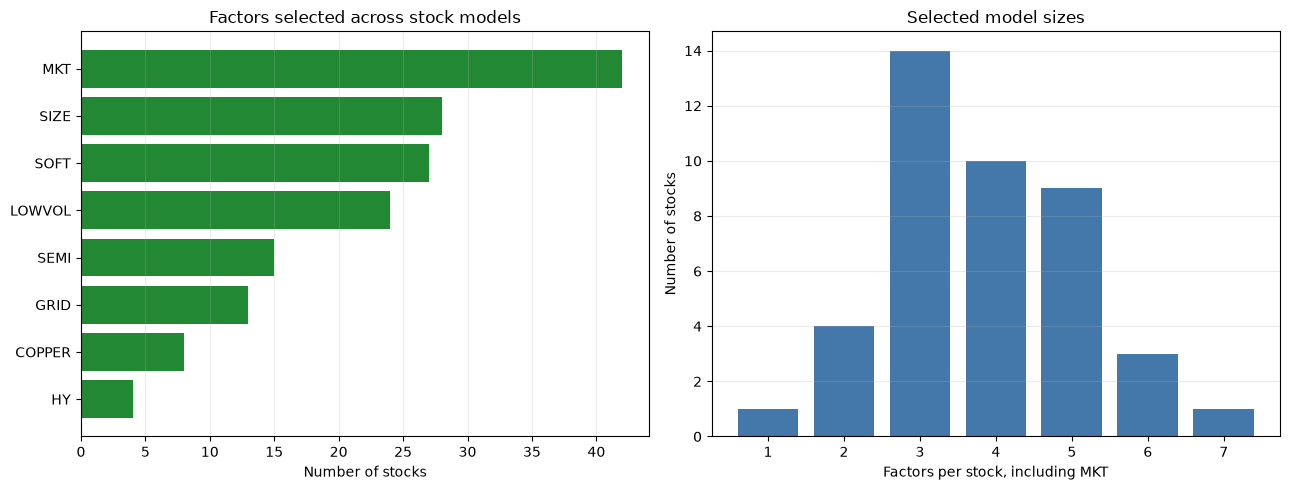

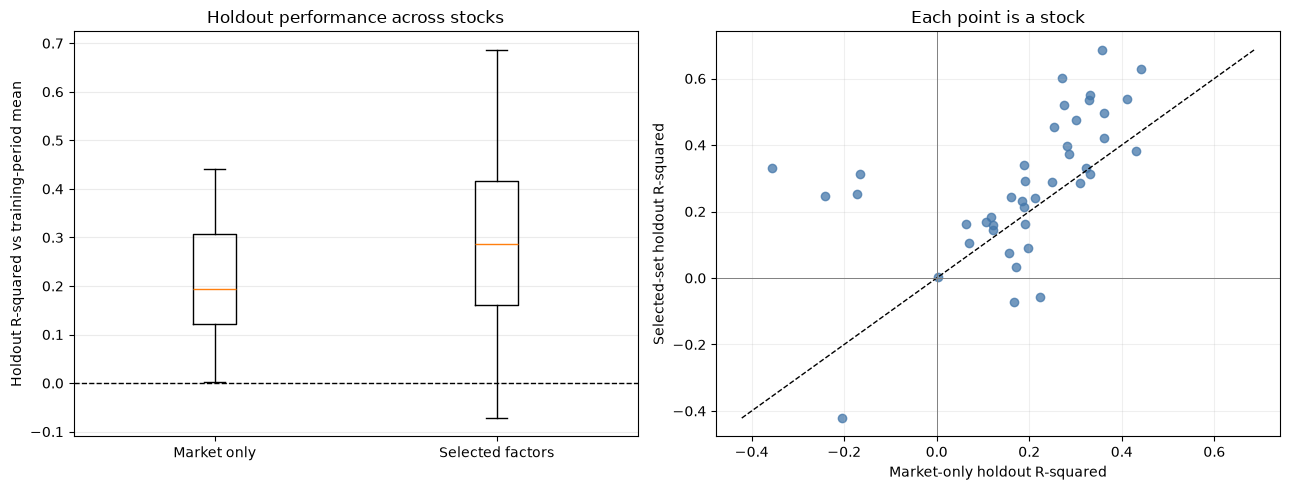

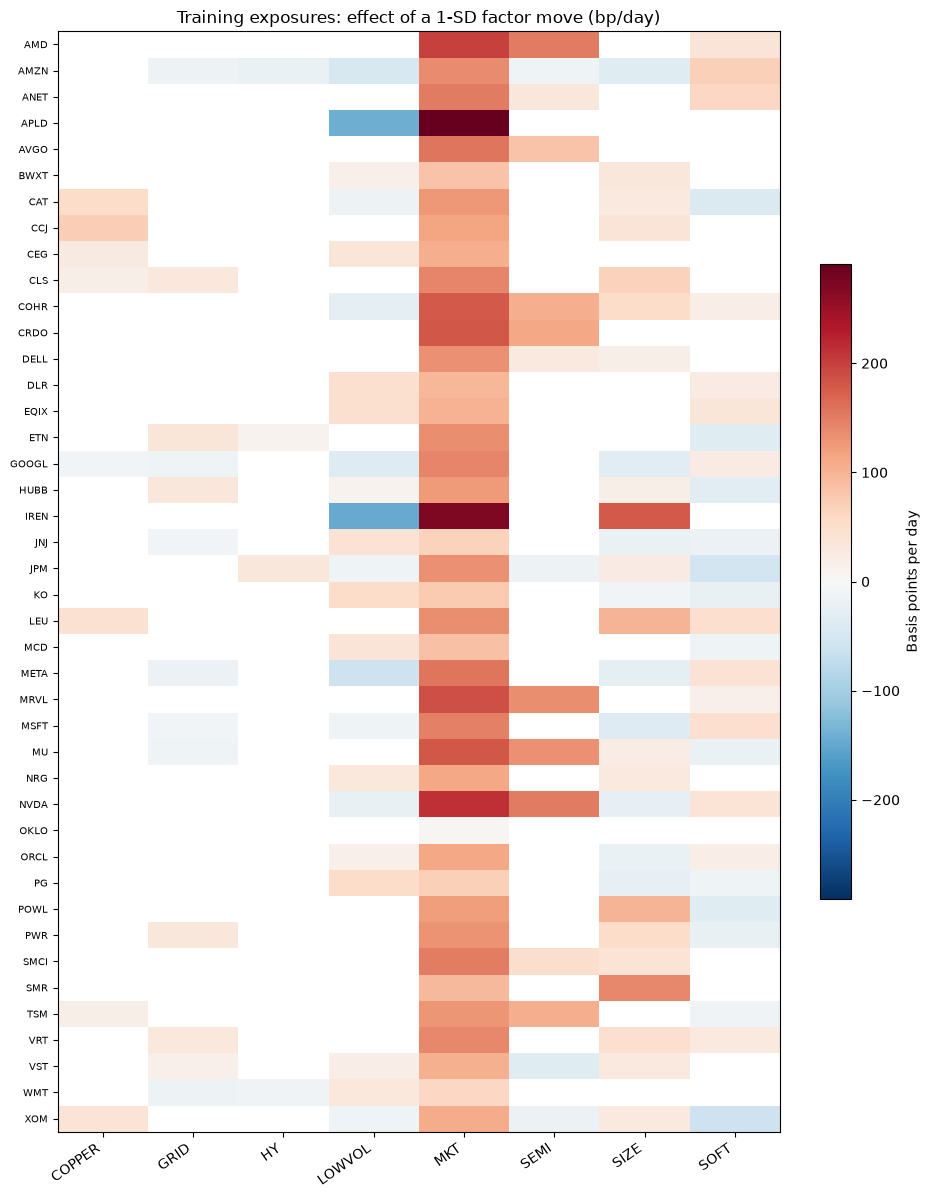

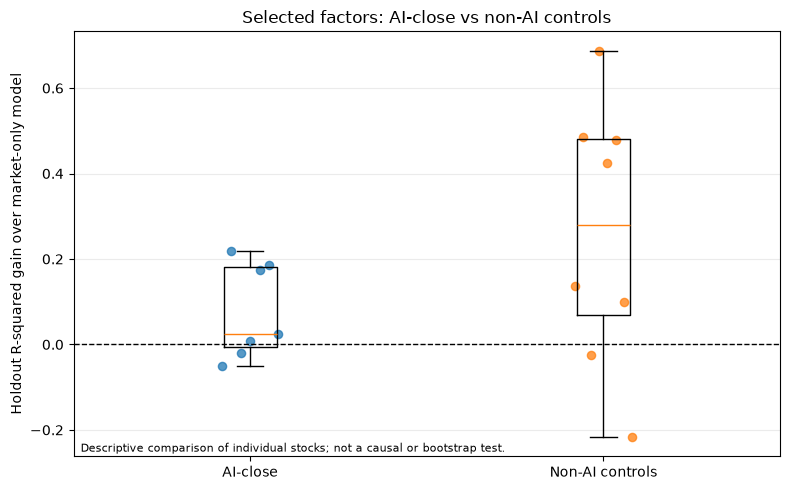

In [3]:
display(
    res["summary"].sort_values("holdout_r2_increment", ascending=False).head(20)
)
display(res["skipped"])
stock_specific_model.plot_factor_selection(selection_results)
stock_specific_model.plot_performance(res)
stock_specific_model.plot_exposure_heatmap(res, selection_results)
ai_specificity = stock_specific_model.plot_ai_specificity(res)

## Inspect one stock

Change `target` to any stock listed in `res["summary"]["target"]`. The prediction dashboard focuses on the holdout and includes actual-versus-predicted returns, an illustrative cumulative-return comparison, and residual diagnostics. The attribution plots decompose the selected stock's holdout returns; the variance shares can be signed because components may offset.

,target,factor,coefficient
141,NVDA,Intercept,0.001204
142,NVDA,MKT,1.779748
143,NVDA,SEMI,1.325225
144,NVDA,SOFT,0.476025
145,NVDA,SIZE,-0.338148
146,NVDA,LOWVOL,-0.687627


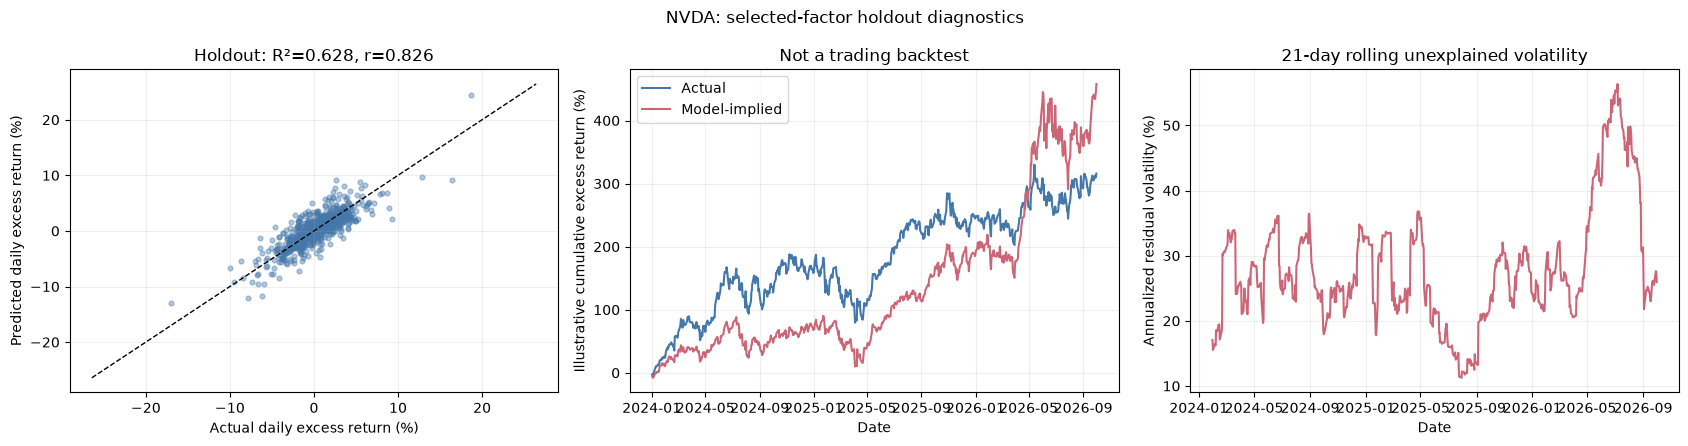

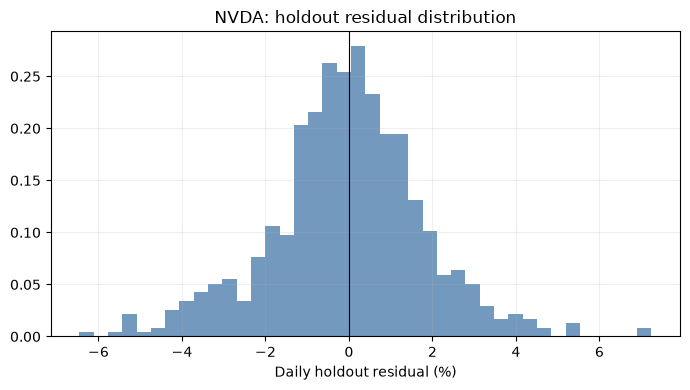

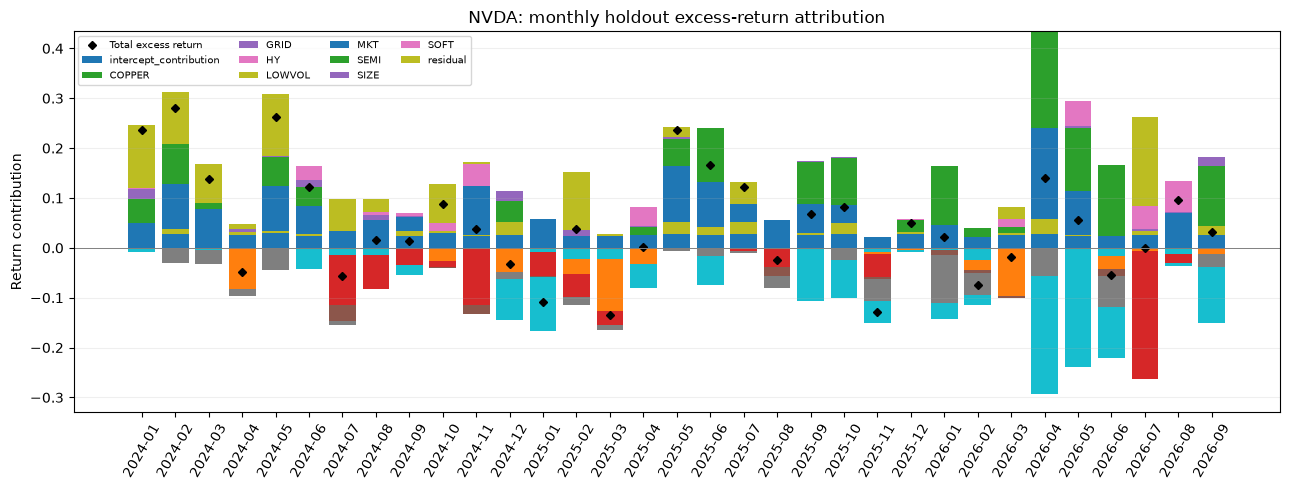

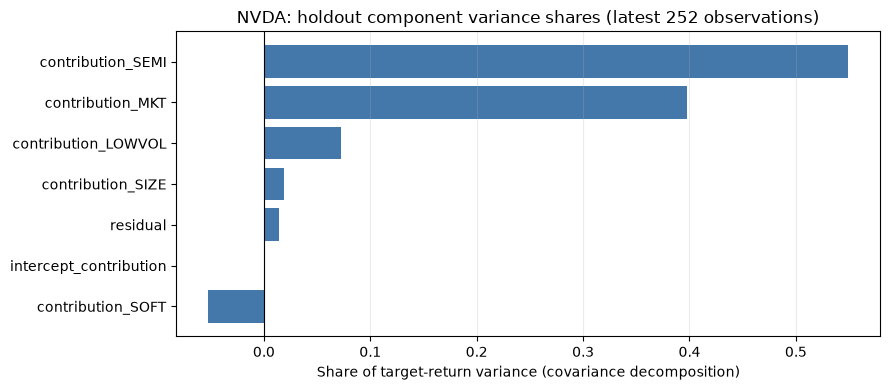

In [4]:
target = "NVDA"
if target not in set(res["summary"]["target"]):
    target = res["summary"].iloc[0]["target"]
display(res["coefficients"].loc[res["coefficients"]["target"] == target])
stock_predictions = stock_specific_model.plot_prediction_diagnostics(res, target)
monthly_attribution, variance_shares = stock_specific_model.plot_stock_attribution(res, target)

The regression coefficients apply to the stock's saved orthogonalized factors. Because those factors were residualized in their selected order, a factor coefficient describes its relationship after removing the components explained by the factors before it. This is an association, not a causal effect.